# ResNet18 для simple

## 1. Данные и разбиение

In [1]:
%pip install -q iterative-stratification tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet18
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from sklearn.metrics import f1_score, precision_score, recall_score, average_precision_score

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / 'data' / 'train.csv').exists())
TRAIN_DIR = ROOT / 'data' / 'train'
MODEL_DIR = ROOT / 'labels' / 'simple' / 'models'
SOURCE_PATH = ROOT / 'archive' / 'models' / 'resnet' / 'best_resnet18_improved.pth'
TARGET = 'simple'
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

train = pd.read_csv(ROOT / 'data' / 'train.csv')
target_columns = train.columns.drop('item_id').tolist()
splitter = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
train_val_index, _ = next(splitter.split(train, train[target_columns]))
train_val_df = train.iloc[train_val_index].reset_index(drop=True)
splitter = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.1765, random_state=43)
train_index, val_index = next(splitter.split(train_val_df, train_val_df[target_columns]))
train_df = train_val_df.iloc[train_index].reset_index(drop=True)
val_df = train_val_df.iloc[val_index].reset_index(drop=True)

print('Train:', len(train_df), 'Validation:', len(val_df))
print('Устройство:', device)

c:\Users\gasre\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Train: 6259 Validation: 1361
Устройство: cpu


## 2. Изображения и DataLoader

In [3]:
val_transform = transforms.Compose([
    transforms.Resize((224, 336)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
train_transform = transforms.Compose([
    transforms.Resize((224, 336)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10),
    transforms.RandomGrayscale(p=0.05),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

class SimpleDataset(Dataset):
    def __init__(self, data, transform):
        self.paths = [TRAIN_DIR / f'{item_id}.png' for item_id in data['item_id']]
        self.targets = data[TARGET].to_numpy(dtype=np.float32)
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            image = self.transform(image.convert('RGB'))
        target = torch.tensor([self.targets[index]], dtype=torch.float32)
        return image, target

BATCH_SIZE = 32
train_loader = DataLoader(SimpleDataset(train_df, train_transform),
                          batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
                          pin_memory=device.type == 'cuda')
val_loader = DataLoader(SimpleDataset(val_df, val_transform),
                        batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
                        pin_memory=device.type == 'cuda')

images, labels = next(iter(train_loader))
print('Batch изображений:', images.shape)
print('Batch меток:', labels.shape)

Batch изображений: torch.Size([32, 3, 224, 336])
Batch меток: torch.Size([32, 1])


## 3. Модель с одним выходом

In [4]:
def build_model():
    checkpoint = torch.load(SOURCE_PATH, map_location='cpu', weights_only=True)
    assert checkpoint['target_columns'] == target_columns

    model = resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, len(target_columns))
    model.load_state_dict(checkpoint['model_state_dict'])

    old_fc = model.fc
    simple_index = target_columns.index(TARGET)
    model.fc = nn.Linear(old_fc.in_features, 1)
    with torch.no_grad():
        model.fc.weight.copy_(old_fc.weight[simple_index:simple_index + 1])
        model.fc.bias.copy_(old_fc.bias[simple_index:simple_index + 1])

    for parameter in model.parameters():
        parameter.requires_grad = False
    for parameter in model.layer4.parameters():
        parameter.requires_grad = True
    for parameter in model.fc.parameters():
        parameter.requires_grad = True
    return model.to(device)

model = build_model()
print('Выходов:', model.fc.out_features)
print('Обучаемых параметров:', sum(p.numel() for p in model.parameters() if p.requires_grad))

Выходов: 1
Обучаемых параметров: 8394241


## 4. Обучение и проверка

In [5]:
def train_epoch(model, optimizer, criterion, epoch, epochs):
    model.train()
    model.bn1.eval()
    model.layer1.eval()
    model.layer2.eval()
    model.layer3.eval()

    total_loss = 0
    for images, labels in tqdm(train_loader, desc=f'Эпоха {epoch}/{epochs}'):
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        loss = criterion(model(images), labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(images)
    return total_loss / len(train_loader.dataset)

def validate(model, criterion):
    model.eval()
    total_loss = 0
    targets, probabilities = [], []
    with torch.inference_mode():
        for images, labels in val_loader:
            logits = model(images.to(device))
            loss = criterion(logits, labels.to(device))
            total_loss += loss.item() * len(images)
            targets.append(labels.numpy().ravel())
            probabilities.append(torch.sigmoid(logits).cpu().numpy().ravel())
    return (total_loss / len(val_loader.dataset),
            np.concatenate(targets), np.concatenate(probabilities))

## 5. Три эпохи

In [6]:
EPOCHS = 3
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
MODEL_DIR.mkdir(exist_ok=True)
MODEL_PATH = MODEL_DIR / 'best_simple_resnet18.pth'

model = build_model()
positive = train_df[TARGET].sum()
negative = len(train_df) - positive
criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor([negative / positive], dtype=torch.float32, device=device)
)
optimizer = torch.optim.AdamW([
    {'params': model.layer4.parameters(), 'lr': 2e-5},
    {'params': model.fc.parameters(), 'lr': 1e-4}
], weight_decay=1e-4)

history = []
best_ap = -1
for epoch in range(1, EPOCHS + 1):
    train_loss = train_epoch(model, optimizer, criterion, epoch, EPOCHS)
    val_loss, y_val, probabilities = validate(model, criterion)
    ap = average_precision_score(y_val, probabilities)
    f1 = f1_score(y_val, probabilities >= 0.5)
    history.append({'epoch': epoch, 'train_loss': train_loss,
                    'val_loss': val_loss, 'F1 при 0.5': f1, 'AP': ap})
    print(f'Эпоха {epoch}: train loss={train_loss:.4f}, '
          f'val loss={val_loss:.4f}, F1={f1:.4f}, AP={ap:.4f}')
    if ap > best_ap:
        best_ap = ap
        torch.save({'model_state_dict': model.state_dict(),
                    'target': TARGET, 'target_columns': target_columns,
                    'epoch': epoch, 'validation_ap': float(ap), 'seed': SEED}, MODEL_PATH)
        print('Сохранена лучшая модель')

history = pd.DataFrame(history)
history

Эпоха 1/3: 100%|██████████| 196/196 [05:21<00:00,  1.64s/it]


Эпоха 1: train loss=0.4597, val loss=0.5411, F1=0.6990, AP=0.7746
Сохранена лучшая модель


Эпоха 2/3: 100%|██████████| 196/196 [04:57<00:00,  1.52s/it]


Эпоха 2: train loss=0.4153, val loss=0.5770, F1=0.6970, AP=0.7681


Эпоха 3/3: 100%|██████████| 196/196 [05:34<00:00,  1.71s/it]


Эпоха 3: train loss=0.3709, val loss=0.5944, F1=0.6994, AP=0.7724


,epoch,train_loss,val_loss,F1 при 0.5,AP
0,1,0.459689,0.541138,0.698972,0.774559
1,2,0.415326,0.577032,0.696970,0.768108
2,3,0.370945,0.594436,0.699367,0.772396


## 6. Результат лучшей эпохи

In [7]:
best_checkpoint = torch.load(MODEL_PATH, map_location=device, weights_only=True)
assert best_checkpoint['target'] == TARGET
model.load_state_dict(best_checkpoint['model_state_dict'])
val_loss, y_val, probabilities = validate(model, criterion)

thresholds = np.arange(0.05, 0.96, 0.01)
scores = [f1_score(y_val, probabilities >= threshold) for threshold in thresholds]
best_threshold = float(thresholds[np.argmax(scores)])
predicted = probabilities >= best_threshold

print('Лучшая эпоха:', best_checkpoint['epoch'])
print('Порог:', round(best_threshold, 2))
print('Precision:', round(precision_score(y_val, predicted), 4))
print('Recall:', round(recall_score(y_val, predicted), 4))
print('F1:', round(f1_score(y_val, predicted), 4))
print('AP:', round(average_precision_score(y_val, probabilities), 4))
print('FP:', int(((y_val == 0) & predicted).sum()))
print('FN:', int(((y_val == 1) & ~predicted).sum()))
print('F1 прежней ResNet18 по simple: 0.6966')
print('F1 прежней связки по simple: 0.7090')

with open(MODEL_DIR / 'simple_resnet18_threshold.json', 'w', encoding='utf-8') as file:
    json.dump({'target': TARGET, 'threshold': best_threshold,
               'validation_f1': float(f1_score(y_val, predicted)),
               'seed': SEED}, file, indent=2)

other_columns = [column for column in target_columns if column not in [TARGET, 'quality']]
mixed = val_df[other_columns].sum(axis=1).gt(0).to_numpy()
for name, mask in [('Только simple', ~mixed), ('Simple + другие', mixed)]:
    selected = (y_val == 1) & mask
    print(name, '| объектов:', int(selected.sum()),
          '| пропущено:', int((selected & ~predicted).sum()))

Лучшая эпоха: 1
Порог: 0.47
Precision: 0.6035
Recall: 0.8374
F1: 0.7014
AP: 0.7746
FP: 159
FN: 47
F1 прежней ResNet18 по simple: 0.6966
F1 прежней связки по simple: 0.7090
Только simple | объектов: 210 | пропущено: 20
Simple + другие | объектов: 79 | пропущено: 27


## 7. График обучения

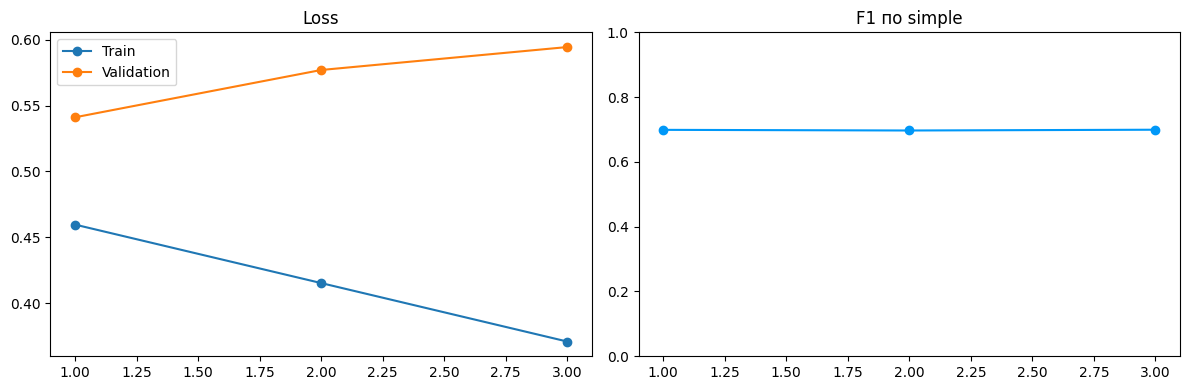

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history['epoch'], history['train_loss'], marker='o', label='Train')
axes[0].plot(history['epoch'], history['val_loss'], marker='o', label='Validation')
axes[0].set_title('Loss')
axes[0].legend()
axes[1].plot(history['epoch'], history['F1 при 0.5'], marker='o', color='#0098F8')
axes[1].set_title('F1 по simple')
axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.show()